# Chapter 4.5 — mathematical illustrations

Run the settings cell, then the setup cell, then either figure cell. These are illustrative populations and parameter values, not empirical results or fitted estimates. No manuscript or acquisition files are modified.

The figures display directly below their cells. Saving is optional; PNG files suit Word and SVG files preserve vector graphics. The final cell saves the population and selection intervals for reproducibility.


In [1]:
from pathlib import Path

# Figure 1: vary one sigmoid parameter while holding the other fixed.
PERFORMANCE_RANGE = (-3.0, 3.0)
SHARPNESS_VALUES = (0.5, 2.0, 8.0)  # gamma: larger means a sharper transition.
FIXED_THRESHOLD = 0.0               # theta for the left panel.
THRESHOLD_VALUES = (-1.0, 0.0, 1.0) # theta: location of the half-relevance point.
FIXED_SHARPNESS = 2.0               # gamma for the right panel.

# Figure 2: each inner tuple is the fixed roster of one group.
GROUP_PERFORMANCES = ((2.6, 2.3, 2.0), (2.4, 1.4, 0.2), (2.1, -0.4, -0.8))
THETA = 1.0
GAMMA = 2.0
K = 3                              # Number selected globally, across all groups.
LAMBDA_RANGE = (0.0, 2.0)           # Only lambda varies within Figure 2.

SAVE_FIGURES = True
OUTPUT_DIRECTORY = Path('/Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5')
# Change OUTPUT_DIRECTORY if running on another computer.

# Figure 3: align scarcity with a reference threshold from performance.
# Each K is a GLOBAL number of places among the same nine individuals.
SCARCITY_PLACES = (3, 1)
SCARCITY_GAMMA = 2.0
SCARCITY_LAMBDA = 2.0
# Illustrative rule: theta = empirical (1 - K/N) quantile of A.
# Linear interpolation is explicit; this rule is not a verified historical fit.
SCARCITY_QUANTILE_METHOD = 'linear'

# Figure 4 (Section 4.6.2): an actual seeded sequential assignment.
ASSIGNMENT_PERFORMANCES = (-1.5, -0.9, -0.3, 0.3, 0.9, 1.5)
ASSIGNMENT_CAPACITIES = (3, 3)  # Two groups for this step-by-step layout.
ASSIGNMENT_RHO = 2.0           # Similarity preference; 0 gives uniform remaining-slot allocation.
ASSIGNMENT_SEED = 42           # Controls both arrival order and assignment draws.


In [2]:
import csv
import json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

OUT = OUTPUT_DIRECTORY
from IPython.display import Image, display
from io import BytesIO
if SAVE_FIGURES:
    OUT.mkdir(parents=True, exist_ok=True)
COLORS = ['#2474A5', '#CE771C', '#33815C']
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.labelsize': 12,
    'svg.fonttype': 'none', 'savefig.facecolor': 'white'})

def sigmoid(a, theta, gamma):
    return 1 / (1 + np.exp(-gamma * (np.asarray(a) - theta)))

def finish(fig, name):
    # Explicit PNG display works even when Cursor shows only a Figure label.
    preview = BytesIO()
    fig.savefig(preview, format='png', dpi=160, bbox_inches='tight')
    display(Image(data=preview.getvalue()))
    if SAVE_FIGURES:
        for suffix in ('png', 'svg'):
            path = OUT / f'{name}.{suffix}'
            fig.savefig(path, dpi=230, bbox_inches='tight')
            print('Saved:', path)
    plt.close(fig)

if len(GROUP_PERFORMANCES) != 3 or any(len(g) != 3 for g in GROUP_PERFORMANCES):
    raise ValueError('This teaching layout requires three groups of three people.')
if GAMMA <= 0 or FIXED_SHARPNESS <= 0 or any(g <= 0 for g in SHARPNESS_VALUES):
    raise ValueError('Sharpness values must be positive.')
if not 1 <= K <= 9:
    raise ValueError('K must be between 1 and 9.')
if not 0 <= LAMBDA_RANGE[0] < LAMBDA_RANGE[1]:
    raise ValueError('Use a nonnegative increasing lambda range.')


## Figure 1 — threshold location and transition sharpness

Suggested placement: in 4.5.1, after explaining the two parameters and before the limiting cases.


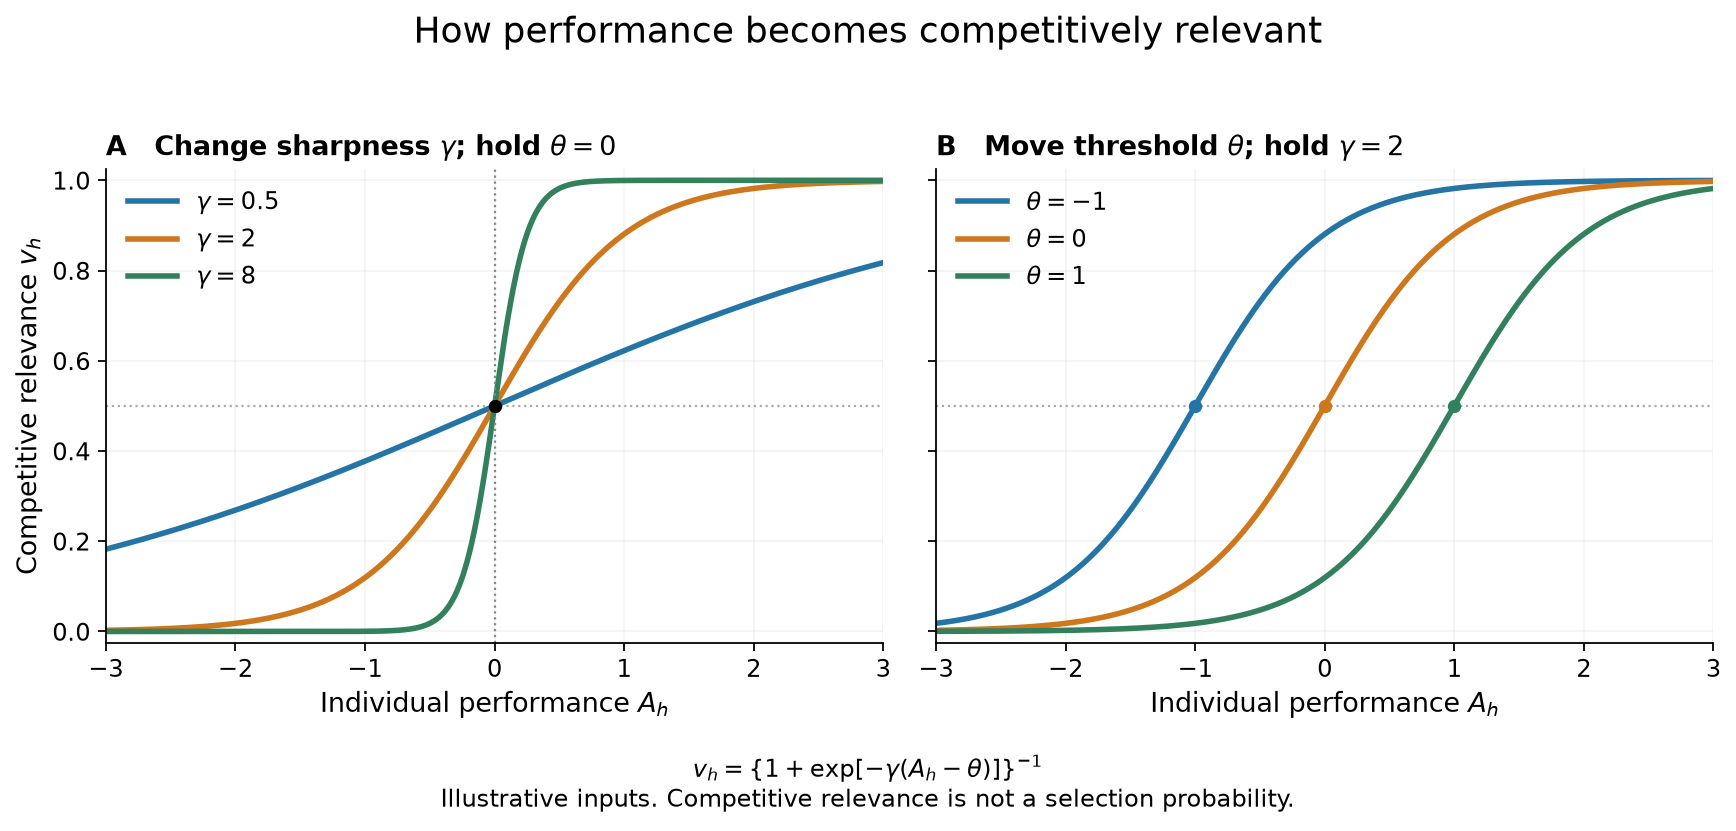

Saved: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/figure_4_5_1_competitive_relevance.png
Saved: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/figure_4_5_1_competitive_relevance.svg


In [3]:
# Figure 1: vary one parameter at a time.
x = np.linspace(*PERFORMANCE_RANGE, 1001)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for gamma, color in zip(SHARPNESS_VALUES, COLORS):
    axs[0].plot(x, sigmoid(x, FIXED_THRESHOLD, gamma), color=color, lw=2.5,
                label=rf'$\gamma={gamma:g}$')
axs[0].axvline(FIXED_THRESHOLD, color='#888888', ls=':', lw=1)
axs[0].scatter([FIXED_THRESHOLD], [.5], color='black', s=25, zorder=5)
axs[0].set_title(rf'A   Change sharpness $\gamma$; hold $\theta={FIXED_THRESHOLD:g}$', loc='left', fontsize=12)
axs[0].legend(loc='upper left', frameon=False)
for theta, color in zip(THRESHOLD_VALUES, COLORS):
    axs[1].plot(x, sigmoid(x, theta, FIXED_SHARPNESS), color=color, lw=2.5,
                label=rf'$\theta={theta:g}$')
    axs[1].scatter([theta], [.5], color=color, s=25, zorder=5)
axs[1].set_title(rf'B   Move threshold $\theta$; hold $\gamma={FIXED_SHARPNESS:g}$', loc='left', fontsize=12)
axs[1].legend(loc='upper left', frameon=False)
for ax in axs:
    ax.axhline(.5, color='#AAAAAA', ls=':', lw=1, zorder=0)
    ax.set(xlim=PERFORMANCE_RANGE, ylim=(-.025,1.025), xlabel=r'Individual performance $A_h$')
    ax.grid(alpha=.14)
axs[0].set_ylabel(r'Competitive relevance $v_h$')
fig.suptitle('How performance becomes competitively relevant', fontsize=16, y=1.02)
fig.text(.5, -.01, r'$v_h=\{1+\exp[-\gamma(A_h-\theta)]\}^{-1}$'
         '\nIllustrative inputs. Competitive relevance is not a selection probability.', ha='center', fontsize=11)
fig.tight_layout(rect=(0,.07,1,.98))
finish(fig, 'figure_4_5_1_competitive_relevance')



## Figure 2 — changing scores and changing winners

Suggested placement: in 4.5.2, after the paragraph explaining score crossings and discrete changes in the selected set, before differentiating the score with respect to own performance. Colors denote groups; bold line segments and colored bars denote selected individuals. Exact boundary ties favor the lower person number.

Changing the inputs changes the example. Annotations are computed from crossings, rather than assuming the default identities or crossing locations.


Roster pressure by group: [0.9 0.6 0.3]; selection-set changes: 1


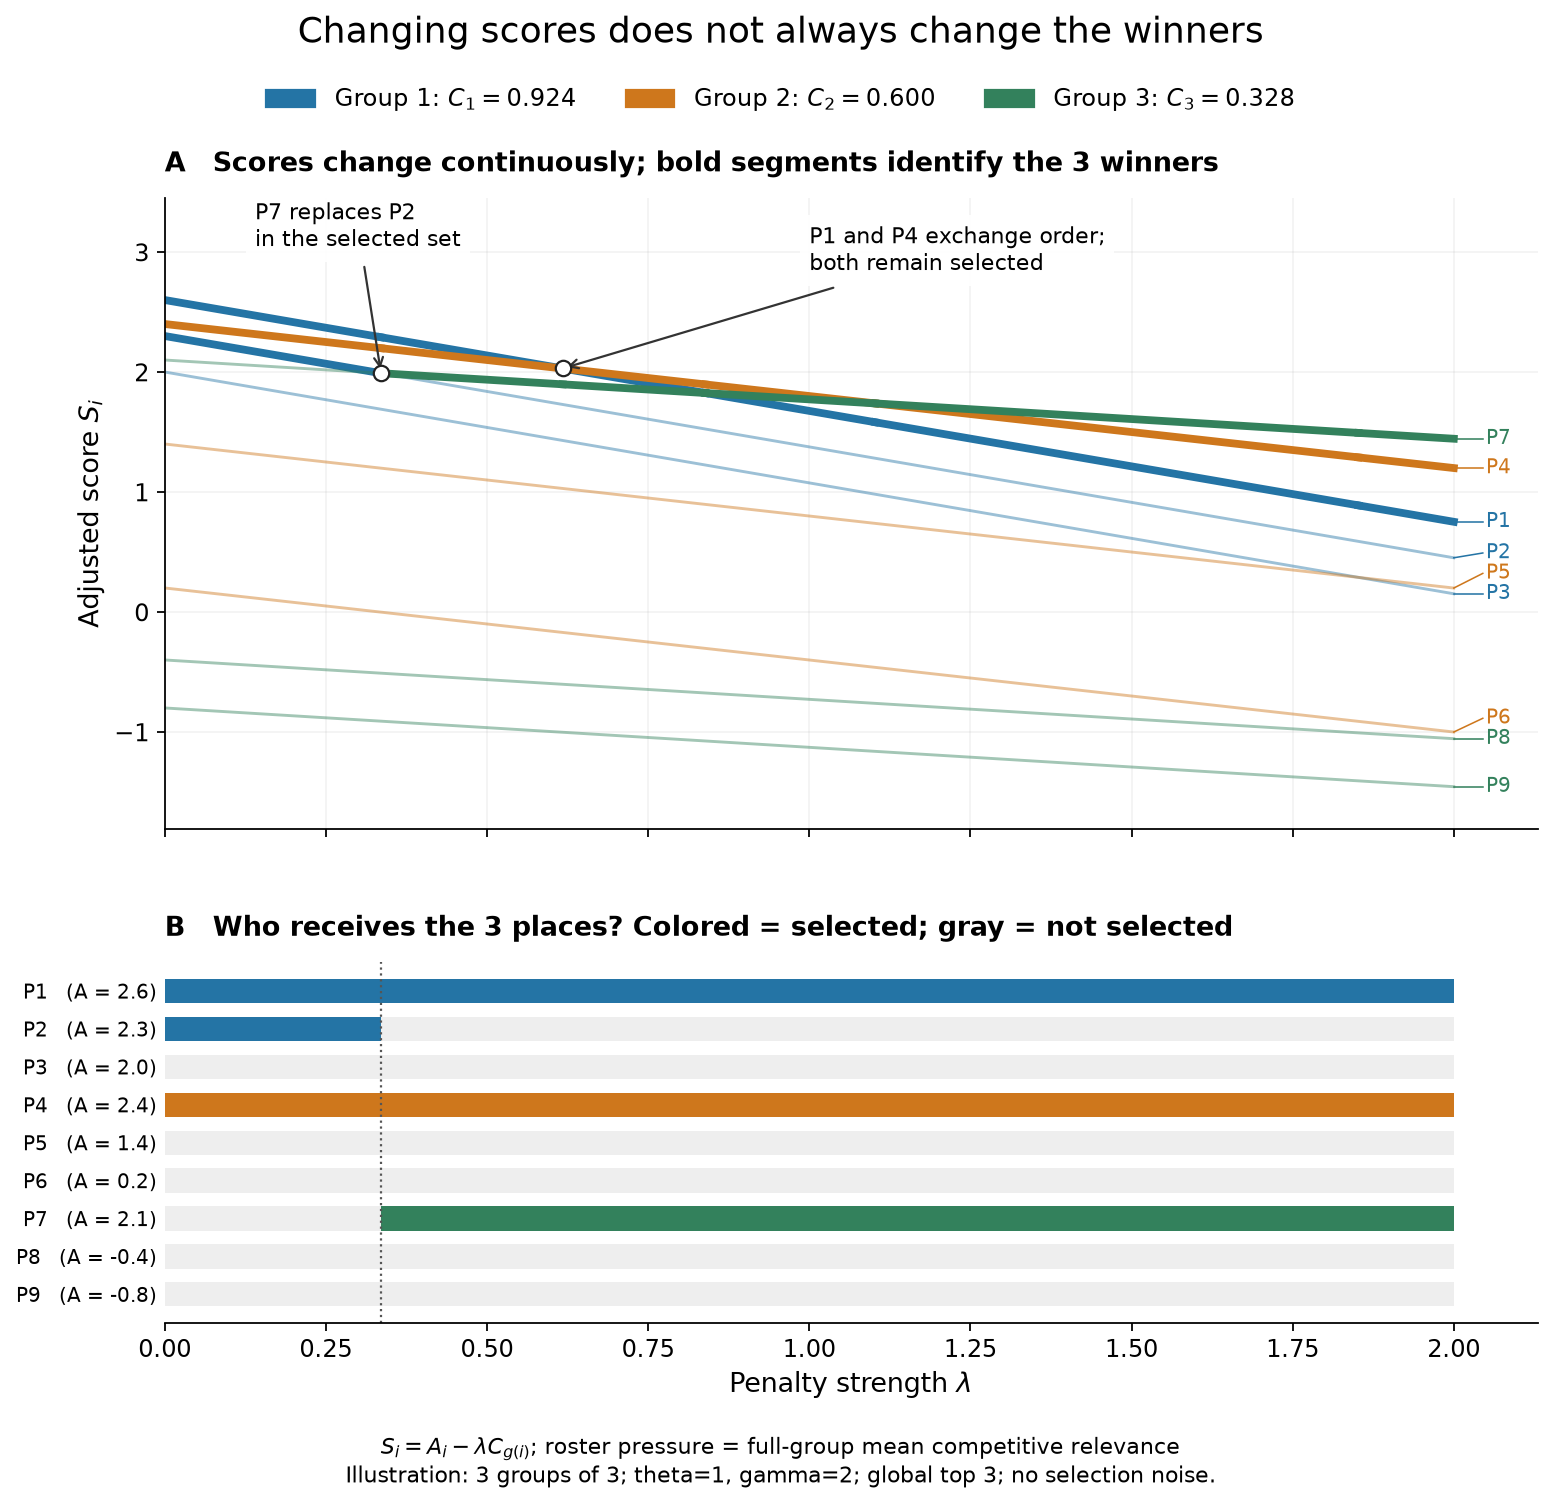

Saved: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/figure_4_5_2_scores_and_winners.png
Saved: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/figure_4_5_2_scores_and_winners.svg


In [4]:
# Figure 2: fixed population, full-group sigmoid mean, then global deterministic top K.
np.set_printoptions(precision=1, floatmode='fixed')
A = np.array(GROUP_PERFORMANCES, dtype=float).ravel()
groups = np.repeat(np.arange(3), 3)
ids = np.array([f'P{i}' for i in range(1, 10)])
theta, gamma = THETA, GAMMA
v = sigmoid(A, theta, gamma)
C = np.array([v[groups == g].mean() for g in range(3)])
lo, hi = LAMBDA_RANGE

def scores(lam):
    return A - lam * C[groups]

def winners(lam):
    # Higher score first, then lower person number at an exact boundary tie.
    return set(np.lexsort((np.arange(len(A)), -scores(lam)))[:K])

# Compute every actual crossing rather than infer winners from a plotting grid.
crossings = []
for i in range(len(A)):
    for h in range(i+1, len(A)):
        dc = C[groups[i]] - C[groups[h]]
        if abs(dc) > 1e-12:
            lam = (A[i] - A[h]) / dc
            if lo < lam < hi:
                crossings.append((float(lam), i, h))
breaks = sorted({lo, hi, *(p[0] for p in crossings)})
changes = [p for p in crossings if winners(p[0]-1e-7) != winners(p[0]+1e-7)]
annotations = []
if changes:
    lam, i, h = changes[0]
    before, after = winners(lam-1e-7), winners(lam+1e-7)
    gained = ', '.join(ids[k] for k in sorted(after-before))
    lost = ', '.join(ids[k] for k in sorted(before-after))
    annotations.append((lam, (i,h), f'{gained} replaces {lost}\nin the selected set',
                        (lo+.07*(hi-lo), max(A)+.45)))
inside = [p for p in crossings if {p[1],p[2]}.issubset(winners(p[0]-1e-7))
          and {p[1],p[2]}.issubset(winners(p[0]+1e-7))]
if inside:
    lam, i, h = inside[0]
    annotations.append((lam, (i,h), f'{ids[i]} and {ids[h]} exchange order;\nboth remain selected',
                        (lo+.50*(hi-lo), max(A)+.25)))
print(f'Roster pressure by group: {C}; selection-set changes: {len(changes)}')

fig, (ax, strip) = plt.subplots(2, 1, figsize=(11, 9.5), sharex=True,
                              gridspec_kw={'height_ratios':[3.5,2.0], 'hspace':.27})
ls = np.linspace(lo, hi, 601)
for person in range(len(A)):
    ax.plot(ls, A[person] - ls*C[groups[person]], color=COLORS[groups[person]],
            lw=1.3, alpha=.45)
    # Bold portions mark membership in the top-K set on each open interval.
    for left,right in zip(breaks[:-1],breaks[1:]):
        if person in winners((left+right)/2):
            ax.plot([left,right], [scores(left)[person],scores(right)[person]],
                    color=COLORS[groups[person]], lw=3.5)
# Separate labels where endpoint scores are close, keeping a leader to each line.
endpoint = scores(hi)
label_y = endpoint.copy()
order = np.argsort(endpoint)
for previous, current in zip(order[:-1], order[1:]):
    label_y[current] = max(label_y[current], label_y[previous] + .17)
for person in range(len(A)):
    ax.plot([hi, hi+.045], [endpoint[person], label_y[person]],
            color=COLORS[groups[person]], lw=.7)
    ax.text(hi+.05, label_y[person], ids[person], color=COLORS[groups[person]],
            fontsize=9, va='center')
ax.set_ylabel(r'Adjusted score $S_i$')
ax.set_title(f'A   Scores change continuously; bold segments identify the {K} winners',
             loc='left', fontsize=12, pad=12)
ax.set_ylim(min(scores(hi))-.35, max(A)+.85)
ax.grid(alpha=.15)
for lam, pair, text, xytext in annotations:
    y = scores(lam)[pair[0]]
    ax.scatter([lam],[y],s=48,facecolor='white',edgecolor='#222222',zorder=8)
    ax.annotate(text, xy=(lam,y), xytext=xytext, fontsize=10,
                arrowprops={'arrowstyle':'->','color':'#333333'},
                bbox={'facecolor':'white','edgecolor':'none','alpha':.95})
for person in range(len(A)):
    strip.broken_barh([(lo,hi-lo)], (person-.32,.64), facecolors='#EEEEEE')
    for left,right in zip(breaks[:-1],breaks[1:]):
        if person in winners((left+right)/2):
            strip.broken_barh([(left,right-left)], (person-.32,.64),
                             facecolors=COLORS[groups[person]])
for lam, _, _ in changes:
    strip.axvline(lam, ls=':', color='#555555', lw=1)
strip.set_yticks(range(len(A)), [f'{p}   (A = {a:.1f})' for p,a in zip(ids,A)])
strip.invert_yaxis()
strip.set_xlabel(r'Penalty strength $\lambda$')
strip.set_title(f'B   Who receives the {K} places? Colored = selected; gray = not selected',
                loc='left', fontsize=12, pad=12)
strip.set_xlim(lo,hi+.13)
strip.set_xticks(np.linspace(lo,hi,9))
strip.spines['left'].set_visible(False)
strip.tick_params(axis='y', length=0, labelsize=9)
fig.suptitle('Changing scores does not always change the winners', fontsize=16, y=.99)
fig.legend(handles=[Patch(color=c, label=rf'Group {g+1}: $C_{g+1}={C[g]:.3f}$')
                    for g,c in enumerate(COLORS)], loc='upper center',
           bbox_to_anchor=(.5,.957), ncol=3, frameon=False)
fig.subplots_adjust(top=.87,bottom=.13,left=.15,right=.93)
fig.text(.5,.025, r'$S_i=A_i-\lambda C_{g(i)}$; roster pressure = full-group mean competitive relevance'
         + f'\nIllustration: 3 groups of 3; theta={theta:g}, gamma={gamma:g}; global top {K}; no selection noise.',
         ha='center', fontsize=10)
finish(fig, 'figure_4_5_2_scores_and_winners')



## Save the exact inputs and selected sets
Run after Figure 2. This records the current notebook settings, not just the defaults.


In [5]:
if SAVE_FIGURES:
    with (OUT / 'illustrative_population.csv').open('w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['person','group','performance_A','competitive_relevance_v','roster_pressure_C'])
        writer.writerows(zip(ids, groups+1, A, v, C[groups]))
    settings = {
        'purpose': 'Mathematical illustration, not empirical estimates',
        'theta': theta, 'gamma': gamma, 'K': K, 'lambda_range': [lo,hi],
        'figure1': {'performance_range': PERFORMANCE_RANGE, 'sharpness_values': SHARPNESS_VALUES,
                    'fixed_threshold': FIXED_THRESHOLD, 'threshold_values': THRESHOLD_VALUES,
                    'fixed_sharpness': FIXED_SHARPNESS},
        'boundary_tie_rule': 'Lower person number first',
        'winner_sets': [{'lambda_interval': [a,b],
                        'winners': sorted(ids[list(winners((a+b)/2))])}
                       for a,b in zip(breaks[:-1],breaks[1:])]
    }
    (OUT / 'illustration_settings.json').write_text(json.dumps(settings, indent=2) + '\n')
    print('Saved population and settings in', OUT)
else:
    print('Saving is switched off; the figures were displayed only.')


Saved population and settings in /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5


## Suggested manuscript captions (default inputs)

Suggested placement: immediately after the corresponding explanation in Section 4.5.

FIGURE 1. How the threshold and transition sharpness determine competitive relevance. Panel A holds theta at zero and varies gamma; all curves pass through relevance one half at the threshold. Panel B holds gamma at two and varies theta, shifting the transition along the performance axis. Performance is expressed in illustrative units. These curves define competitive relevance, not a probability of selection.

FIGURE 2. Continuous score changes and discrete changes in the selected set. Nine illustrative individuals belong to three fixed groups of three. The threshold is theta=1 and gamma=2. Roster pressure is computed as the full-group mean of competitive relevance, including the focal individual, and held fixed as lambda varies. Scores are then used to select the global top three. In Panel A, group colors distinguish the three shared congestion values; parallel lines within each group reflect the common penalty. Bold segments indicate selected individuals. Panel B shows membership directly. P7 replaces P2 at lambda approximately 0.336. At lambda approximately 0.617, P4 overtakes P1, but both remain selected. At an exact tie, lower person number takes precedence; the colored interval widths cannot depict an isolated endpoint. The inputs were chosen to illustrate these distinctions and are not empirical estimates.


If settings change, update the caption values and person labels accordingly.

## Figure 3 — scarcity and threshold move together

Run settings and setup first, then this cell. Earlier figure cells are not required. Each scenario recomputes competitive relevance, full-group roster pressure, adjusted scores, and global deterministic selection. The reference threshold is based on original performance, not adjusted scores.

This quantile rule illustrates broad alignment; it does not commit the manuscript to this exact threshold specification.


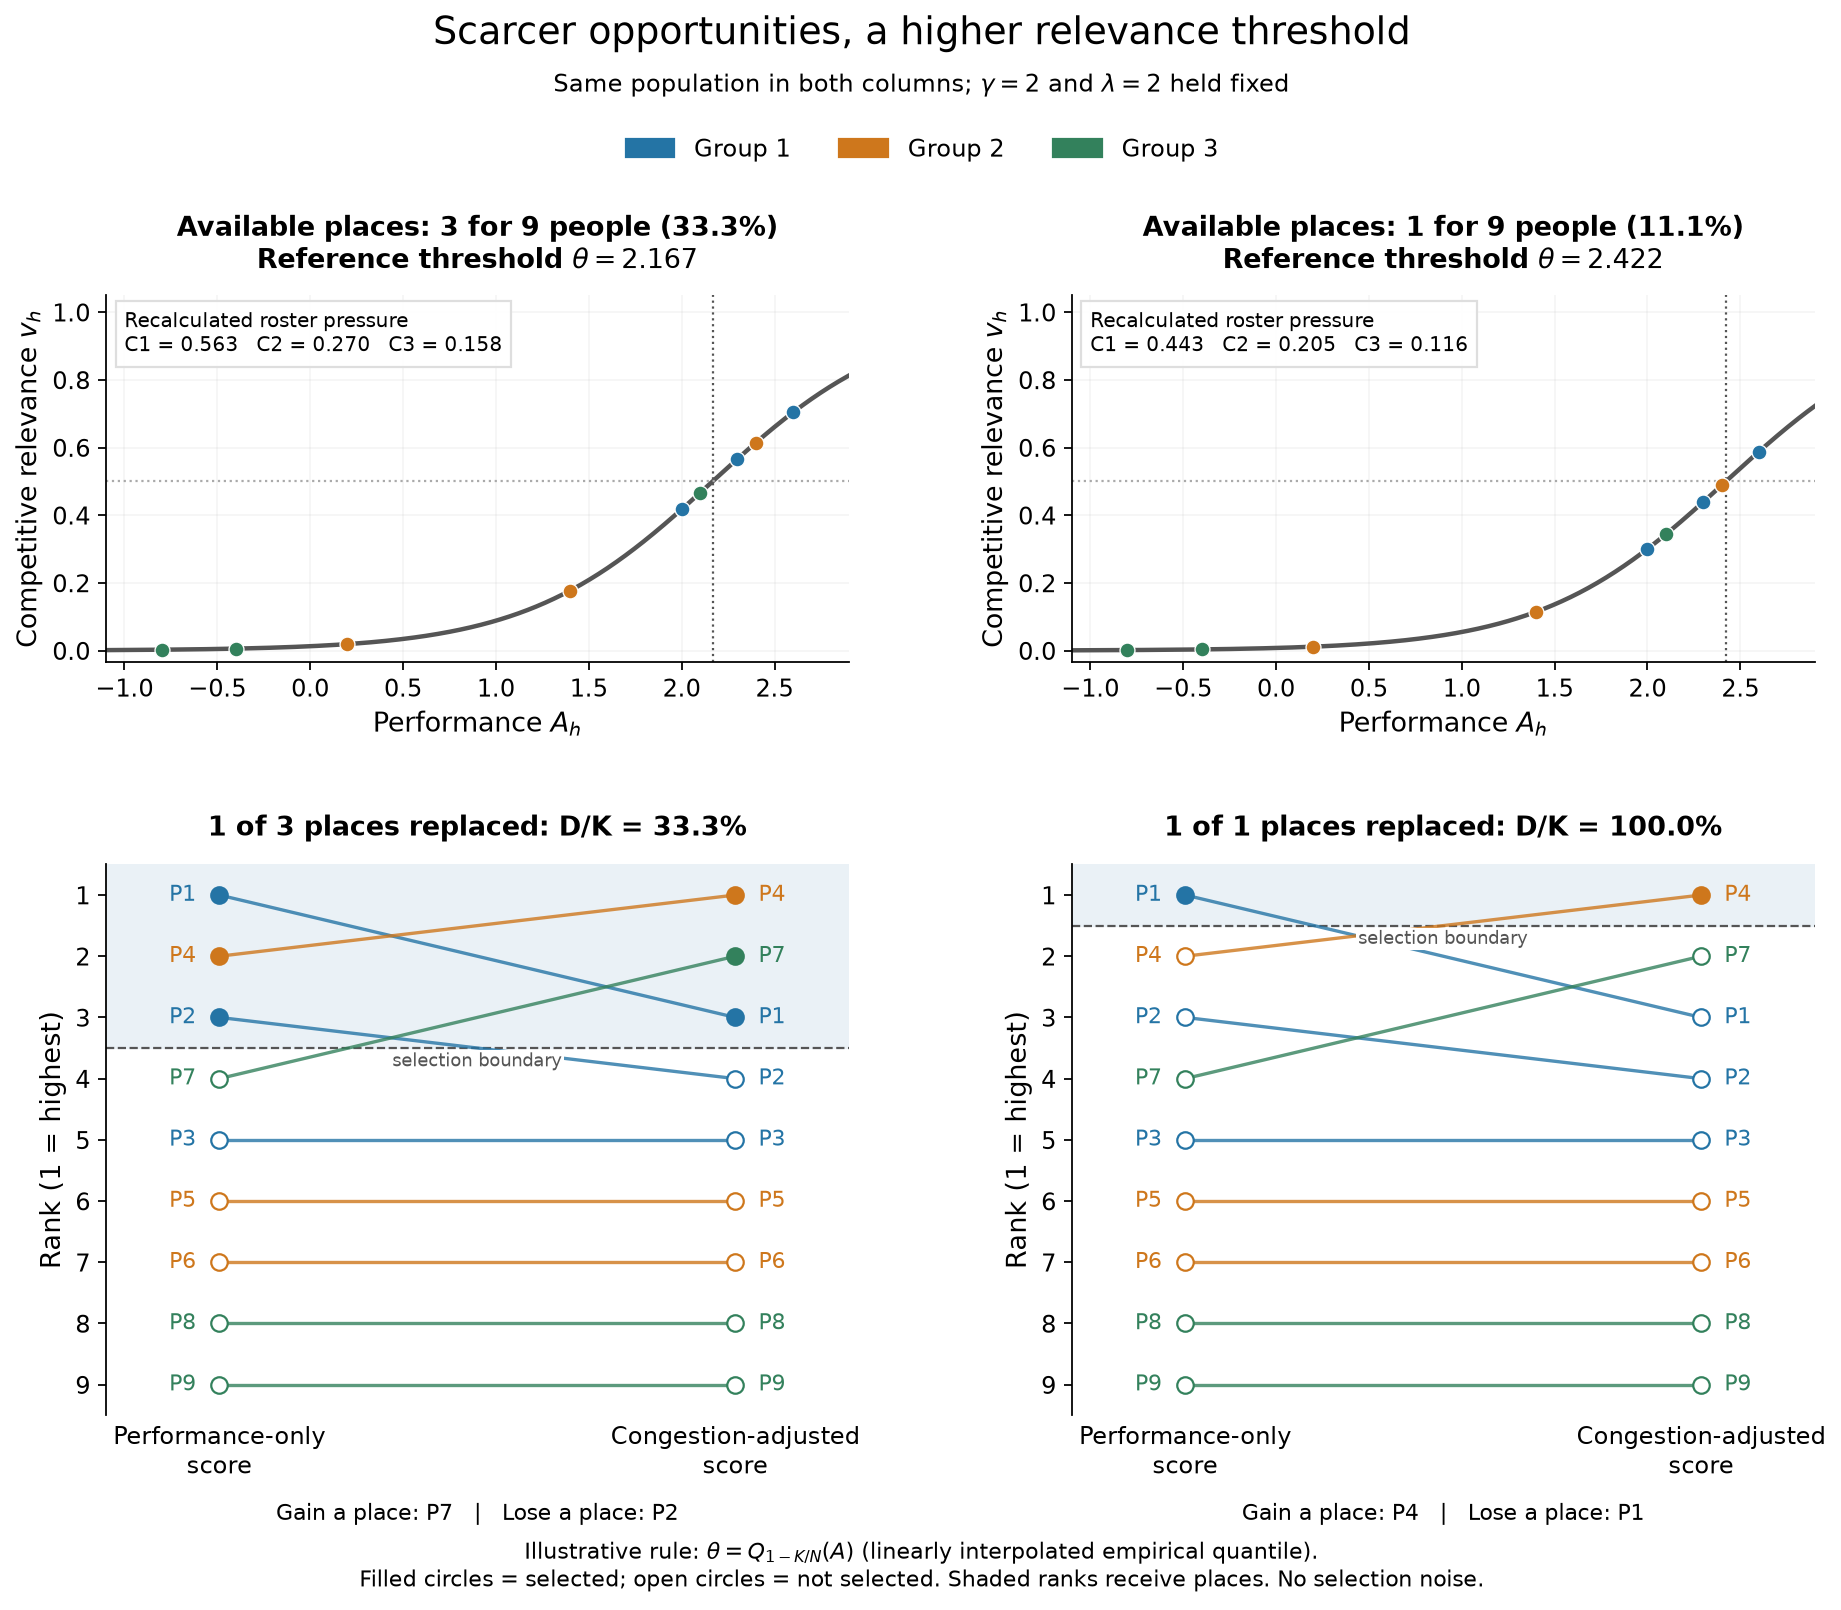

Saved: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/figure_4_5_3_scarcity_and_threshold.png
Saved: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/figure_4_5_3_scarcity_and_threshold.svg
K=3: theta=2.167; benchmark ['P1', 'P4', 'P2']; adjusted ['P4', 'P7', 'P1']; 1 replaced.
K=1: theta=2.422; benchmark ['P1']; adjusted ['P4']; 1 replaced.


In [6]:
# Standalone Figure 3 calculation: does not depend on running Figures 1 or 2.
from matplotlib.patches import Patch
scar_A = np.array(GROUP_PERFORMANCES, dtype=float).ravel()
scar_groups = np.repeat(np.arange(len(GROUP_PERFORMANCES)), [len(g) for g in GROUP_PERFORMANCES])
scar_ids = np.array([f'P{i+1}' for i in range(len(scar_A))])
scar_N = len(scar_A)
if len(SCARCITY_PLACES) != 2 or any(not isinstance(k, int) or not 1 <= k < scar_N for k in SCARCITY_PLACES):
    raise ValueError('Choose two integer values of K, each between 1 and N-1.')
if SCARCITY_GAMMA <= 0 or SCARCITY_LAMBDA < 0:
    raise ValueError('Use gamma > 0 and lambda >= 0.')
scar_order0 = np.lexsort((np.arange(scar_N), -scar_A))
scar_rank0 = np.empty(scar_N, dtype=int)
scar_rank0[scar_order0] = np.arange(1, scar_N+1)
scar_records = []
fig3, axes3 = plt.subplots(2, 2, figsize=(12, 10), gridspec_kw={'height_ratios':[1,1.5]})
fig3.subplots_adjust(top=.82, bottom=.12, left=.075, right=.965, hspace=.44, wspace=.30)
for col, k in enumerate(SCARCITY_PLACES):
    q = k/scar_N
    threshold = float(np.quantile(scar_A, 1-q, method=SCARCITY_QUANTILE_METHOD))
    relevance = sigmoid(scar_A, threshold, SCARCITY_GAMMA)
    pressure = np.array([relevance[scar_groups==g].mean() for g in range(len(GROUP_PERFORMANCES))])
    adjusted = scar_A - SCARCITY_LAMBDA * pressure[scar_groups]
    order = np.lexsort((np.arange(scar_N), -adjusted))
    ranks = np.empty(scar_N, dtype=int)
    ranks[order] = np.arange(1,scar_N+1)
    before, after = set(scar_order0[:k]), set(order[:k])
    gained, lost = after-before, before-after
    d = len(gained)
    assert d == k-len(before & after) == len(lost)
    top, bottom = axes3[:,col]
    grid = np.linspace(min(scar_A)-.3, max(scar_A)+.3, 500)
    top.plot(grid, sigmoid(grid,threshold,SCARCITY_GAMMA), color='#555555', lw=2)
    for g,color in enumerate(COLORS):
        mask=scar_groups==g
        top.scatter(scar_A[mask],relevance[mask],color=color,s=45,zorder=4,edgecolors='white',lw=.6)
    top.axvline(threshold,color='#555555',ls=':',lw=1)
    top.axhline(.5,color='#AAAAAA',ls=':',lw=1)
    top.set(xlim=(grid[0],grid[-1]),ylim=(-.035,1.05),xlabel=r'Performance $A_h$',ylabel=r'Competitive relevance $v_h$')
    top.set_title(f'Available places: {k} for {scar_N} people ({100*q:.1f}%)\n'
                  +rf'Reference threshold $\theta={threshold:.3f}$',fontsize=12,pad=12)
    top.text(.025,.96,'Recalculated roster pressure\n'+'   '.join(f'C{g+1} = {c:.3f}' for g,c in enumerate(pressure)),
             transform=top.transAxes,va='top',fontsize=9,
             bbox={'facecolor':'white','edgecolor':'#DDDDDD','alpha':.95})
    top.grid(alpha=.12)
    bottom.axhspan(.5,k+.5,color='#EAF1F6',zorder=0)
    bottom.axhline(k+.5,color='#555555',ls='--',lw=1)
    bottom.text(.5,k+.57,'selection boundary',ha='center',va='top',fontsize=8,color='#555555',
                bbox={'facecolor':'white','edgecolor':'none','pad':1})
    for person in range(scar_N):
        color=COLORS[scar_groups[person]]
        bottom.plot([0,1],[scar_rank0[person],ranks[person]],color=color,lw=1.5,alpha=.8)
        for x,r,selected in [(0,scar_rank0[person],person in before),(1,ranks[person],person in after)]:
            bottom.scatter(x,r,s=55,facecolor=color if selected else 'white',edgecolor=color,zorder=4)
        bottom.text(-.045,scar_rank0[person],scar_ids[person],ha='right',va='center',color=color,fontsize=10)
        bottom.text(1.045,ranks[person],scar_ids[person],ha='left',va='center',color=color,fontsize=10)
    bottom.set(xlim=(-.22,1.22),ylim=(scar_N+.5,.5),ylabel='Rank (1 = highest)',
               xticks=[0,1],xticklabels=['Performance-only\nscore','Congestion-adjusted\nscore'],yticks=np.arange(1,scar_N+1))
    bottom.tick_params(axis='x',length=0)
    bottom.spines['bottom'].set_visible(False)
    bottom.set_title(f'{d} of {k} places replaced: D/K = {d/k:.1%}',fontsize=12,pad=13)
    gaintext=', '.join(scar_ids[i] for i in sorted(gained)) or 'none'
    losstext=', '.join(scar_ids[i] for i in sorted(lost)) or 'none'
    bottom.text(.5,-.19,f'Gain a place: {gaintext}   |   Lose a place: {losstext}',
                transform=bottom.transAxes,ha='center',fontsize=10)
    scar_records.append({'K':k,'N':scar_N,'selection_fraction':q,'theta':threshold,
        'gamma':SCARCITY_GAMMA,'lambda':SCARCITY_LAMBDA,'group_pressure':pressure.tolist(),
        'relevance':relevance.tolist(),'adjusted_scores':adjusted.tolist(),
        'benchmark_winners':scar_ids[scar_order0[:k]].tolist(),'adjusted_winners':scar_ids[order[:k]].tolist(),
        'replaced_places':d,'fraction_replaced':d/k})
fig3.suptitle('Scarcer opportunities, a higher relevance threshold',fontsize=17,y=.995)
fig3.text(.5,.947,rf'Same population in both columns; $\gamma={SCARCITY_GAMMA:g}$ and $\lambda={SCARCITY_LAMBDA:g}$ held fixed',
          ha='center',fontsize=11)
fig3.legend(handles=[Patch(color=c,label=f'Group {g+1}') for g,c in enumerate(COLORS)],
            loc='upper center',bbox_to_anchor=(.5,.932),ncol=3,frameon=False)
fig3.text(.5,.013,r'Illustrative rule: $\theta=Q_{1-K/N}(A)$ (linearly interpolated empirical quantile).'
          '\nFilled circles = selected; open circles = not selected. Shaded ranks receive places. No selection noise.',
          ha='center',fontsize=10)
finish(fig3, 'figure_4_5_3_scarcity_and_threshold')
if SAVE_FIGURES:
    (OUT/'figure_4_5_3_inputs_and_results.json').write_text(json.dumps({
        'purpose':'Illustrative aligned-threshold construction, not a historical calibration or empirical finding',
        'threshold_rule':'empirical quantile at 1 - K/N','quantile_method':SCARCITY_QUANTILE_METHOD,
        'group_performances':GROUP_PERFORMANCES,'tie_rule':'Lower person number first','scenarios':scar_records
    },indent=2)+'\n')
for row in scar_records:
    print(f"K={row['K']}: theta={row['theta']:.3f}; benchmark {row['benchmark_winners']}; "
          f"adjusted {row['adjusted_winners']}; {row['replaced_places']} replaced.")


### Suggested caption (default settings)

Figure 3. Scarcity and competitive relevance change together. The same nine individuals are considered with three places available (left) and one place available (right). For this illustration, theta is the linearly interpolated empirical (1-K/N)-quantile of performance. Gamma=2 and lambda=2 remain fixed. The upper panels show competitive relevance at each threshold; colored points represent individuals, and the reported group means give the recalculated roster pressures. The lower panels compare performance-only and congestion-adjusted rankings within each scenario. Shading marks the selected ranks, filled circles identify selected individuals, and connecting lines trace each individual across scoring rules. One place is replaced in each scenario, corresponding to one third of the three-place selection and all of the one-place selection. This constructed example illustrates the procedure; it does not establish a general relationship between scarcity and the size of the congestion effect. The threshold rule is an explicit illustrative choice, not a verified historical calibration.

## Figure 4 — Section 4.6.2: sequential assignment

Run the main settings and setup cells, then the cell below. Previous figure cells are not required. The figure uses an actual seeded random arrival order and probability-weighted assignments. Full groups are excluded by zero weight. The trace records pre-draw probabilities and post-draw states separately.

Suggested placement: after the paragraph ending “the procedure fills every group exactly,” before the paragraph discussing rho=0.


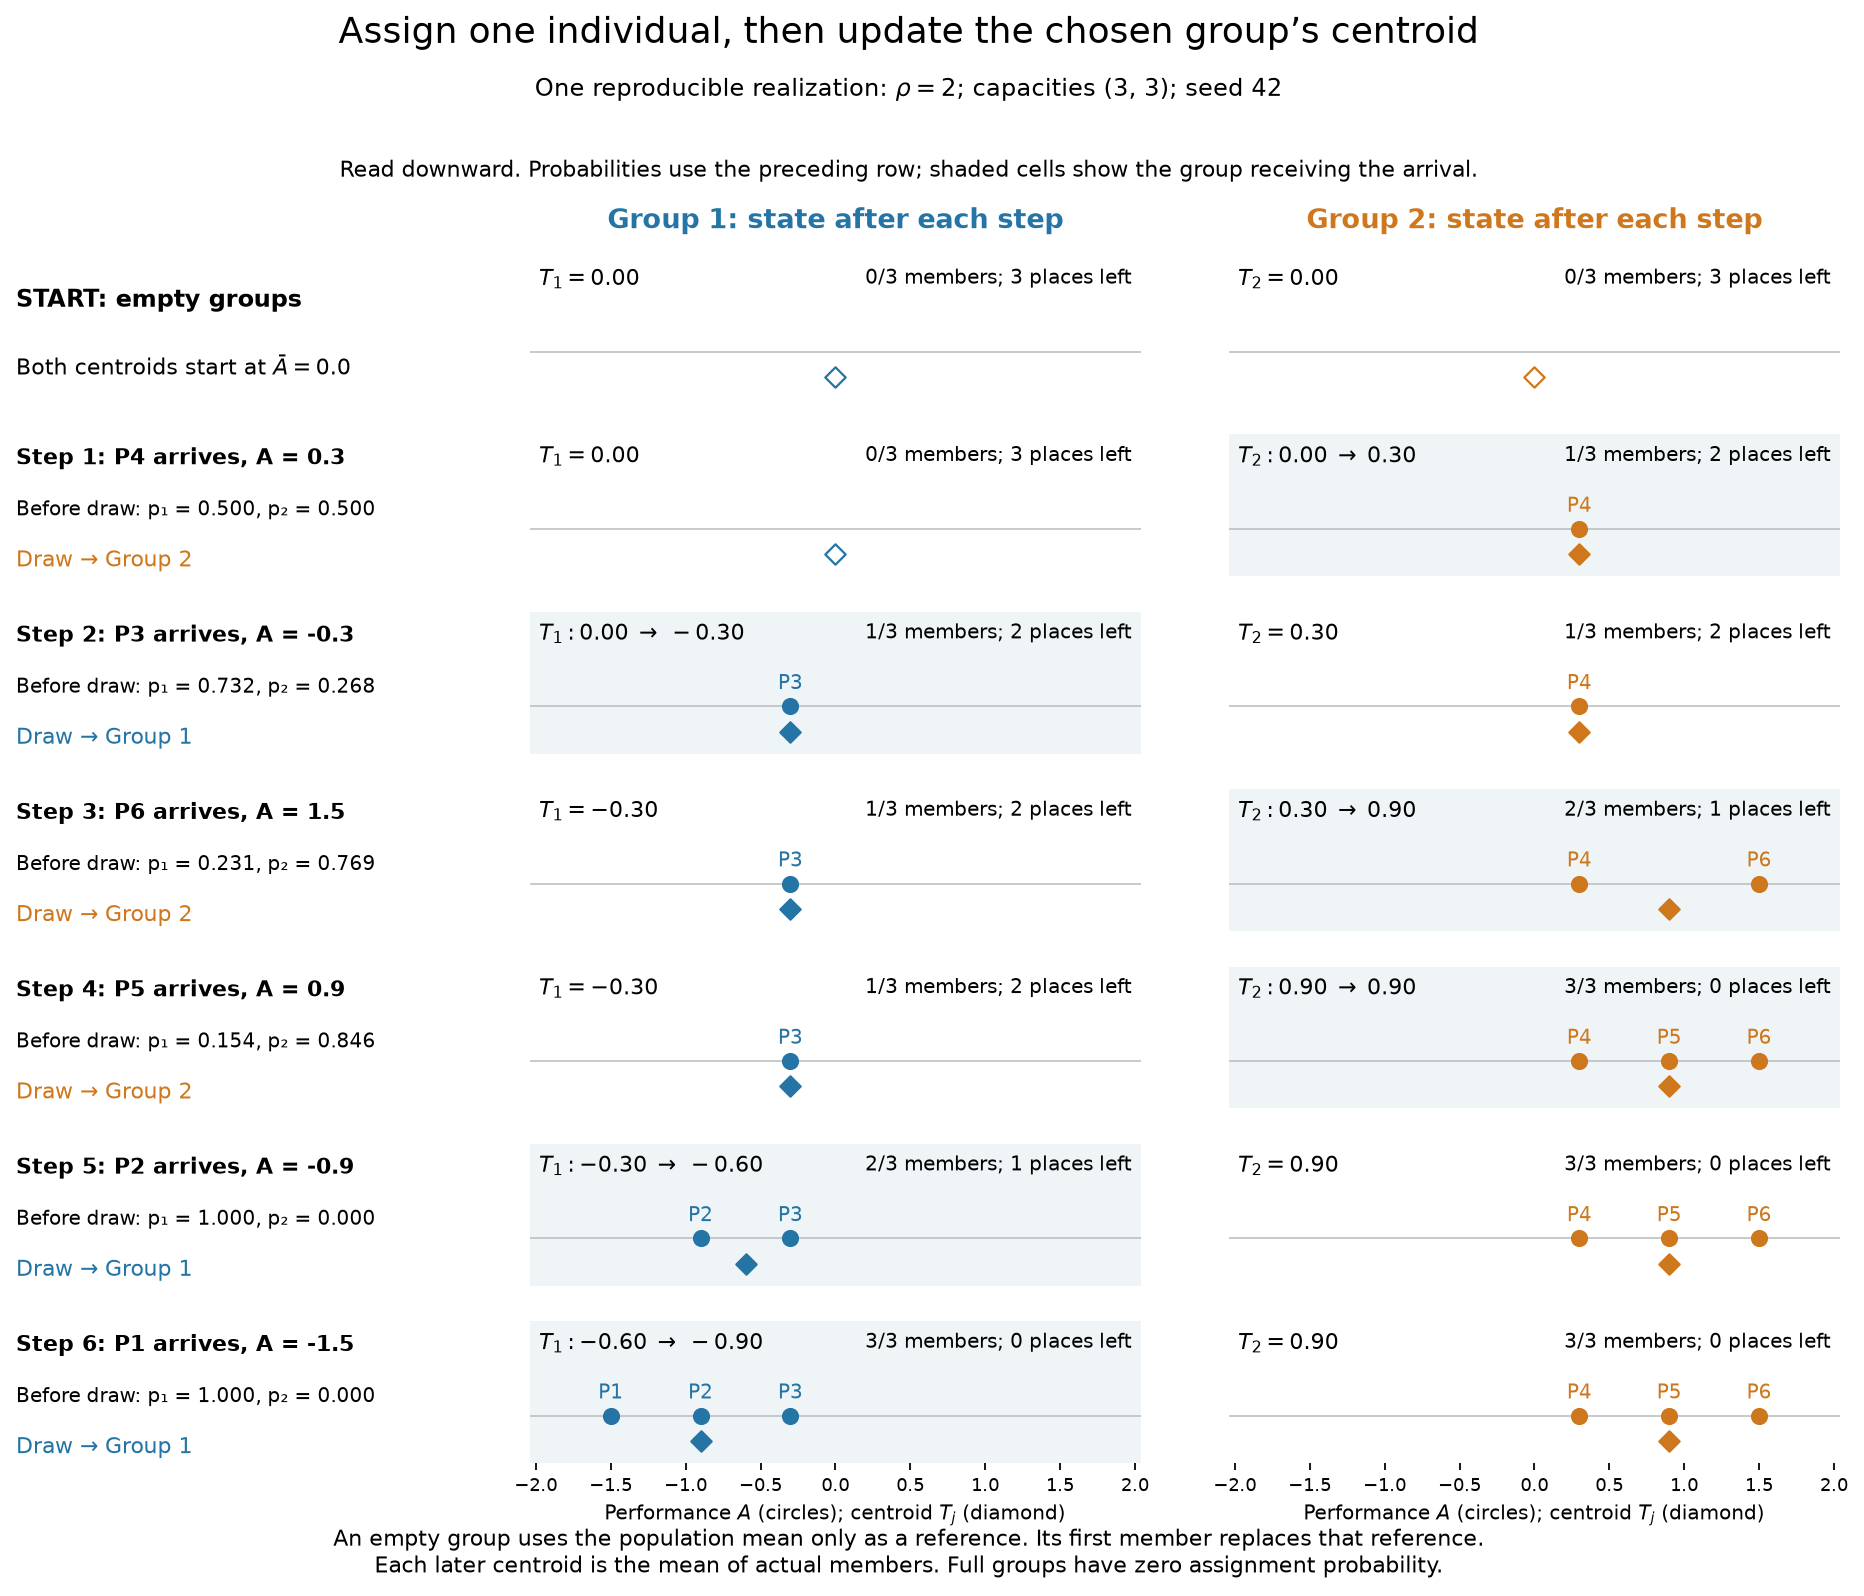

Saved: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/figure_4_6_2_sequential_assignment.png
Saved: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/figure_4_6_2_sequential_assignment.svg
Arrival order: P4 → P3 → P6 → P5 → P2 → P1
Final memberships: [['P3', 'P2', 'P1'], ['P4', 'P6', 'P5']]
Final centroids: [-0.9  0.9]


In [7]:
# Figure 4: calculate probabilities BEFORE each draw; show group states AFTER it.
assignment_a = np.asarray(ASSIGNMENT_PERFORMANCES, dtype=float)
assignment_capacity = np.asarray(ASSIGNMENT_CAPACITIES)
if len(assignment_capacity) != 2 or any(assignment_capacity <= 0) or not np.all(assignment_capacity == assignment_capacity.astype(int)):
    raise ValueError('This layout requires two positive integer group capacities.')
if assignment_capacity.sum() != len(assignment_a) or not np.all(np.isfinite(assignment_a)):
    raise ValueError('Total capacity must equal the number of finite performance values.')
if not np.isfinite(ASSIGNMENT_RHO) or ASSIGNMENT_RHO < 0:
    raise ValueError('Use a finite nonnegative rho.')
assignment_rng = np.random.default_rng(ASSIGNMENT_SEED)
arrival_order = assignment_rng.permutation(len(assignment_a))
assignment_mean = float(assignment_a.mean())
remaining = assignment_capacity.astype(int).copy()
centroids = np.full(2, assignment_mean)
rosters = [[], []]
history = [{'step':0, 'rosters':[[],[]], 'centroids':centroids.tolist(), 'remaining':remaining.tolist()}]
for step, person in enumerate(arrival_order, 1):
    before_centroids = centroids.copy()
    before_remaining = remaining.copy()
    # Log weights preserve the mathematical probabilities at large finite rho.
    log_weights = np.full(2, -np.inf)
    eligible = remaining > 0
    log_weights[eligible] = np.log(remaining[eligible]) - ASSIGNMENT_RHO*np.abs(assignment_a[person]-centroids[eligible])
    weights = np.exp(log_weights - np.max(log_weights))
    probabilities = weights/weights.sum()
    chosen = int(assignment_rng.choice(2, p=probabilities))
    rosters[chosen].append(int(person))
    remaining[chosen] -= 1
    centroids[chosen] = assignment_a[rosters[chosen]].mean()
    history.append({'step':step,'person':int(person),'chosen_group':chosen,
        'before_centroids':before_centroids.tolist(),'before_remaining':before_remaining.tolist(),
        'probabilities':probabilities.tolist(),'rosters':[r.copy() for r in rosters],
        'centroids':centroids.tolist(),'remaining':remaining.tolist()})
assert np.all(remaining == 0)
assert sorted(p for r in rosters for p in r) == list(range(len(assignment_a)))
for event in history[1:]:
    assert np.isclose(sum(event['probabilities']),1)
    for g in range(2):
        expected = assignment_a[event['rosters'][g]].mean() if event['rosters'][g] else assignment_mean
        assert np.isclose(event['centroids'][g], expected)

nrows=len(history)
fig4, assignment_axes = plt.subplots(nrows,3, figsize=(12,1.15*nrows+2.0),
    gridspec_kw={'width_ratios':[1.15,1.65,1.65]})
fig4.subplots_adjust(top=.84,bottom=.09,left=.035,right=.985,hspace=.25,wspace=.16)
span = max(float(np.ptp(assignment_a)), 1.0)
xmin,xmax = min(assignment_a)-.18*span,max(assignment_a)+.18*span
for row,event in enumerate(history):
    info=assignment_axes[row,0];info.axis('off')
    if row==0:
        info.text(0,.65,'START: empty groups',weight='bold',fontsize=11)
        info.text(0,.17,rf'Both centroids start at $\bar A={assignment_mean:.1f}$',fontsize=10)
    else:
        person=event['person']; probs=event['probabilities']
        info.text(0,.79,f"Step {row}: P{person+1} arrives, A = {assignment_a[person]:.1f}",weight='bold',fontsize=10)
        info.text(0,.43,f'Before draw: p₁ = {probs[0]:.3f}, p₂ = {probs[1]:.3f}',fontsize=9)
        info.text(0,.07,f"Draw → Group {event['chosen_group']+1}",fontsize=10,color=COLORS[event['chosen_group']])
    for g in range(2):
        ax=assignment_axes[row,g+1];color=COLORS[g]
        ax.set(xlim=(xmin,xmax),ylim=(-.6,1.2),yticks=[])
        for spine in ax.spines.values():spine.set_visible(False)
        ax.axhline(0,color='#BBBBBB',lw=.7)
        if row and event['chosen_group']==g:ax.set_facecolor('#EFF4F7')
        for person in event['rosters'][g]:
            ax.scatter(assignment_a[person],0,color=color,s=45,zorder=3)
            ax.text(assignment_a[person],.22,f'P{person+1}',ha='center',fontsize=9,color=color)
        centroid=event['centroids'][g]
        ax.scatter(centroid,-.32,marker='D',s=42,edgecolor=color,
                   facecolor=color if event['rosters'][g] else 'white',zorder=4)
        if row and event['chosen_group']==g:
            old=event['before_centroids'][g]
            desc=rf'$T_{g+1}: {old:.2f}\;\rightarrow\;{centroid:.2f}$'
        else:desc=rf'$T_{g+1}={centroid:.2f}$'
        count=len(event['rosters'][g]);cap=int(assignment_capacity[g])
        ax.text(.015,.92,desc,transform=ax.transAxes,va='top',fontsize=10)
        ax.text(.985,.92,f'{count}/{cap} members; {event["remaining"][g]} places left',
                transform=ax.transAxes,ha='right',va='top',fontsize=9)
        if row==0:ax.set_title(f'Group {g+1}: state after each step',fontsize=12,color=color,pad=13)
        if row==nrows-1:
            ax.set_xlabel(r'Performance $A$ (circles); centroid $T_j$ (diamond)',fontsize=9)
            ax.tick_params(axis='x',labelsize=8,length=3)
        else:ax.set_xticks([])
fig4.suptitle('Assign one individual, then update the chosen group’s centroid',fontsize=16,y=.99)
fig4.text(.5,.94,rf'One reproducible realization: $\rho={ASSIGNMENT_RHO:g}$; capacities {tuple(ASSIGNMENT_CAPACITIES)}; seed {ASSIGNMENT_SEED}',
          ha='center',fontsize=11)
fig4.text(.5,.89,'Read downward. Probabilities use the preceding row; shaded cells show the group receiving the arrival.',
          ha='center',fontsize=10)
fig4.text(.5,.022,'An empty group uses the population mean only as a reference. Its first member replaces that reference.'
          '\nEach later centroid is the mean of actual members. Full groups have zero assignment probability.',
          ha='center',fontsize=10)
finish(fig4,'figure_4_6_2_sequential_assignment')
if SAVE_FIGURES:
    (OUT/'figure_4_6_2_assignment_trace.json').write_text(json.dumps({
        'purpose':'Illustrative seeded assignment, not an empirical estimate',
        'performance_values':assignment_a.tolist(),'capacities':assignment_capacity.tolist(),
        'rho':ASSIGNMENT_RHO,'seed':ASSIGNMENT_SEED,'population_mean':assignment_mean,
        'arrival_order':[f'P{i+1}' for i in arrival_order],'history':history},indent=2)+'\n')
print('Arrival order:', ' → '.join(f'P{i+1}' for i in arrival_order))
print('Final memberships:', [[f'P{i+1}' for i in group] for group in rosters])
print('Final centroids:', centroids)


### Caption (default settings)

Sequential assignment with evolving group centroids. Six individuals with performance values A=(-1.5,-0.9,-0.3,0.3,0.9,1.5) are assigned to two groups of capacity three using rho=2. Both empty groups begin with the population mean, A-bar=0, as their centroid reference. Read from top to bottom. Each step reports the arriving individual, the assignment probabilities calculated from the preceding group state, and the group drawn. The two group panels show membership after that assignment; shading identifies the group that received the individual. Circles mark members' performance values, and diamonds mark current centroids. The first member replaces an empty group's reference; subsequent centroids average actual members only. A full group receives zero probability. The random arrival order and assignments use seed 42. This is one illustrative realization, not a deterministic sorting sequence.

Update the caption if you change the settings.

## Section 4.5.4: original versus changed year window

**Left column: original 2009–2021. Right column: 2011–2021.**

**Top row: all eligible players. Bottom row: top performance band.** All four plots include all eligible teams and one final-season observation per player. Bin boundaries are identical; vertical axes match within each row. The top-percent cutoff is recalculated within each window.

Run the settings, loading and plotting cells below. This comparison does not replace the saved manuscript figure. The caption below still describes that original manuscript figure, not this four-panel comparison.


In [8]:
# Visible settings for the empirical comparison only.
BASKETBALL_TOP_PERCENT = 7.0  # Top 7% by pooled within-season PPM z score; includes ties at cutoff.
BASKETBALL_N_BINS = 16       # Equal-width bins defined ONCE from the full cohort's peer range.
BASKETBALL_SHARED_Y = False # False: readable separate y scales, explicitly labeled. True: same scale.
BASKETBALL_THIN_N = 30      # Open markers below this count; no observations silently removed.
BASKETBALL_SAVE = True      # Save PNG, SVG, PDF, bin counts and provenance next to the notebook.


In [9]:
# Load the original cohort from local data; no new simulation, fitting, or downloading.
from pathlib import Path
import importlib.util
search_roots = [Path.cwd(), *Path.cwd().parents]
figure_dir = next((q for p in search_roots for q in (
    p, p / "manuscript_figures/section_4_5",
    p / "3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5")
    if (q / "create_section_4_5_4_figure.py").exists()), None)
if figure_dir is None:
    raise FileNotFoundError("Run from the repository or set figure_dir to manuscript_figures/section_4_5.")
spec = importlib.util.spec_from_file_location("basketball_454", figure_dir / "create_section_4_5_4_figure.py")
basketball_454 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(basketball_454)
basketball_panel, basketball_reference_edges = basketball_454.load_verified_cohort()


Reconstructing saved-specification basketball cohort from local data...
Last-season cross-section · 54,582 → 22,795 rows · 22,795 athletes
Verified historical cohort totals, top-7% cutoff, and all 16 original overall bin counts.


In [ ]:
# Replot the loaded cohort with the visible settings above.
from IPython.display import display, Image
from io import BytesIO
import matplotlib.pyplot as plt
basketball_fig, basketball_bins = basketball_454.make_year_comparison(
    basketball_panel, basketball_reference_edges,
    top_percent=BASKETBALL_TOP_PERCENT, n_bins=BASKETBALL_N_BINS,
    thin_n=BASKETBALL_THIN_N, save=BASKETBALL_SAVE, output_dir=figure_dir)
image_bytes = BytesIO()
basketball_fig.savefig(image_bytes, format="png", dpi=150)
display(Image(data=image_bytes.getvalue()))
plt.close(basketball_fig)
display(basketball_bins[["panel", "bin", "n", "drafted", "team_seasons", "rate", "ci_low", "ci_high"]])


### Suggested introduction

A combined selection curve can conceal differences among individuals with comparable performance. Figure X compares the full basketball cohort with its top 7% by individual performance, using the same peer-performance intervals in both panels. The comparison illustrates how restricting individual performance changes the descriptive question. The horizontal axis measures average teammate performance excluding the focal player, rather than the full-group mean T_j. Neither curve by itself identifies an effect of congestion.

### Caption for default settings

Selection across peer environments in the full basketball cohort and its top performance band. Both panels use the same 2009–2021 final-season cohort and 16 equal-width intervals of mean teammate performance, excluding the focal player. Own performance is measured by points per minute standardized within season; the right panel includes players at or above the pooled 93rd percentile. The outcome is whether the player was ever drafted, not selection during that particular season. Peer scores retain the historical 1st/99th-percentile winsorization. Points show within-bin draft proportions; error bars are pointwise 95% Wilson intervals without adjustment for team clustering. Counts below each panel give players and distinct team-seasons. Open circles identify bins with fewer than 30 players; empty bins have no plotted rate. The vertical scales differ. These descriptive comparisons do not establish that congestion caused the observed patterns.

Use Word’s figure cross-reference in place of Figure X. Update caption numbers if the settings change. The right panel is a performance band, not an exact control for individual performance. Team-season counts are not independent-observation counts, and the intervals do not account for teammate dependence.


## Year-window comparisons for mosaic panels 9, 7 and 8

Each row compares the original year window with the requested window. Panel 9 remains all eligible teams and one final-season observation per player. Panels 7 and 8 retain their original drafted-team restriction and all player-seasons. Panel 7 retains own-performance z in [2,3]; panel 8 retains the top-7% rule.

**Important:** panel 9 retains its original peer scaling and exact bin edges. Panels 7 and 8 use saved window-specific reruns: team eligibility, bin boundaries, winsorization and the top-7% cutoff are recalculated by their original rules. These are year-window specification comparisons, not a fixed-team, fixed-boundary experiment. Error bars do not account for repeated players or team clustering.

The manuscript figure is not replaced. Set `REBUILD_YEAR_COMPARISON = True` to rebuild from local sources; otherwise this cell displays the saved comparisons.

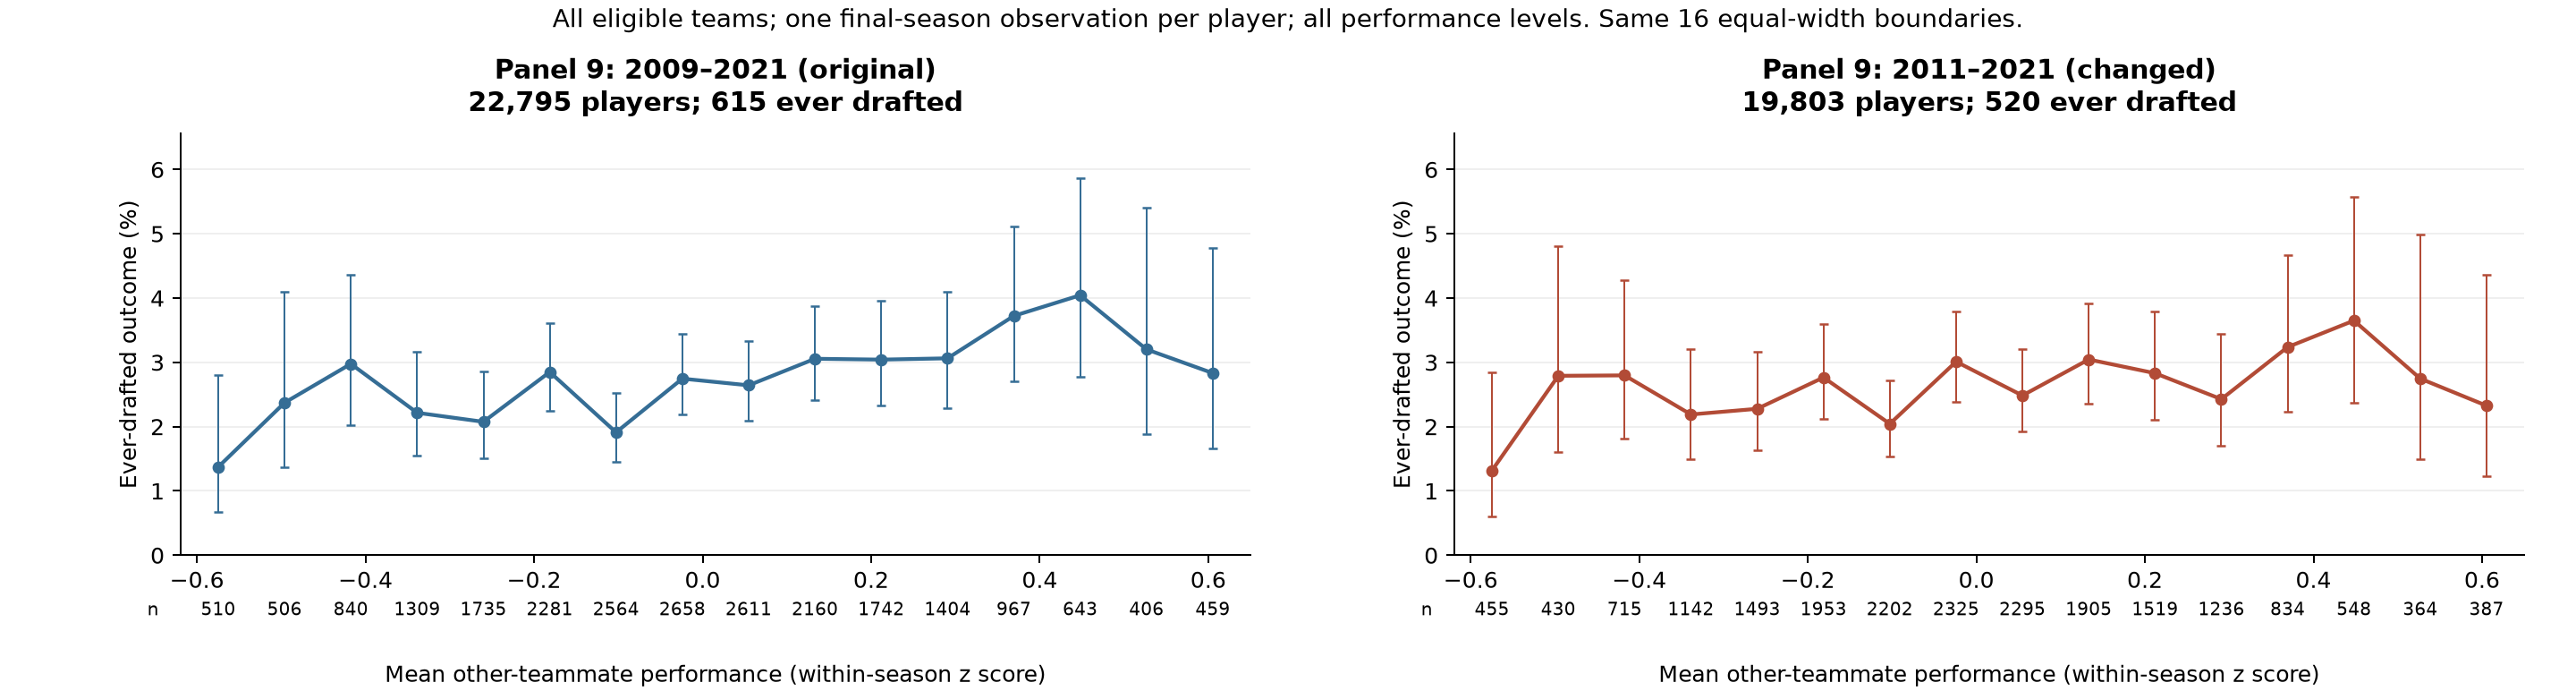

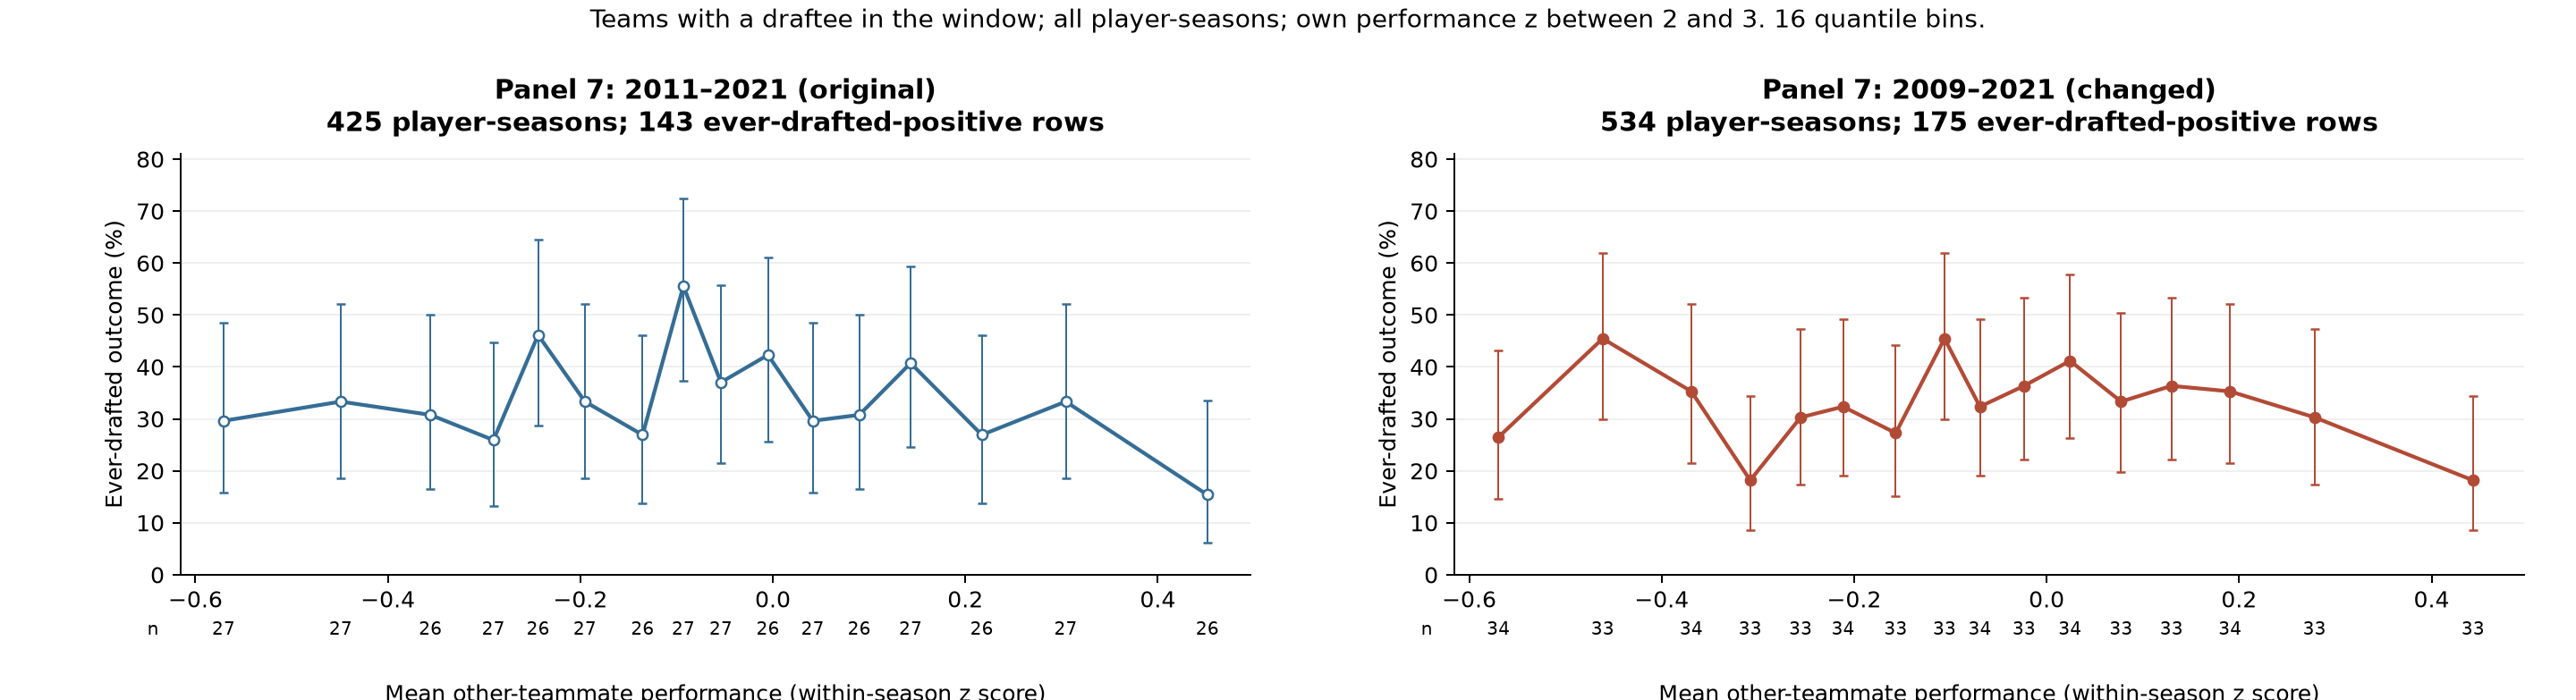

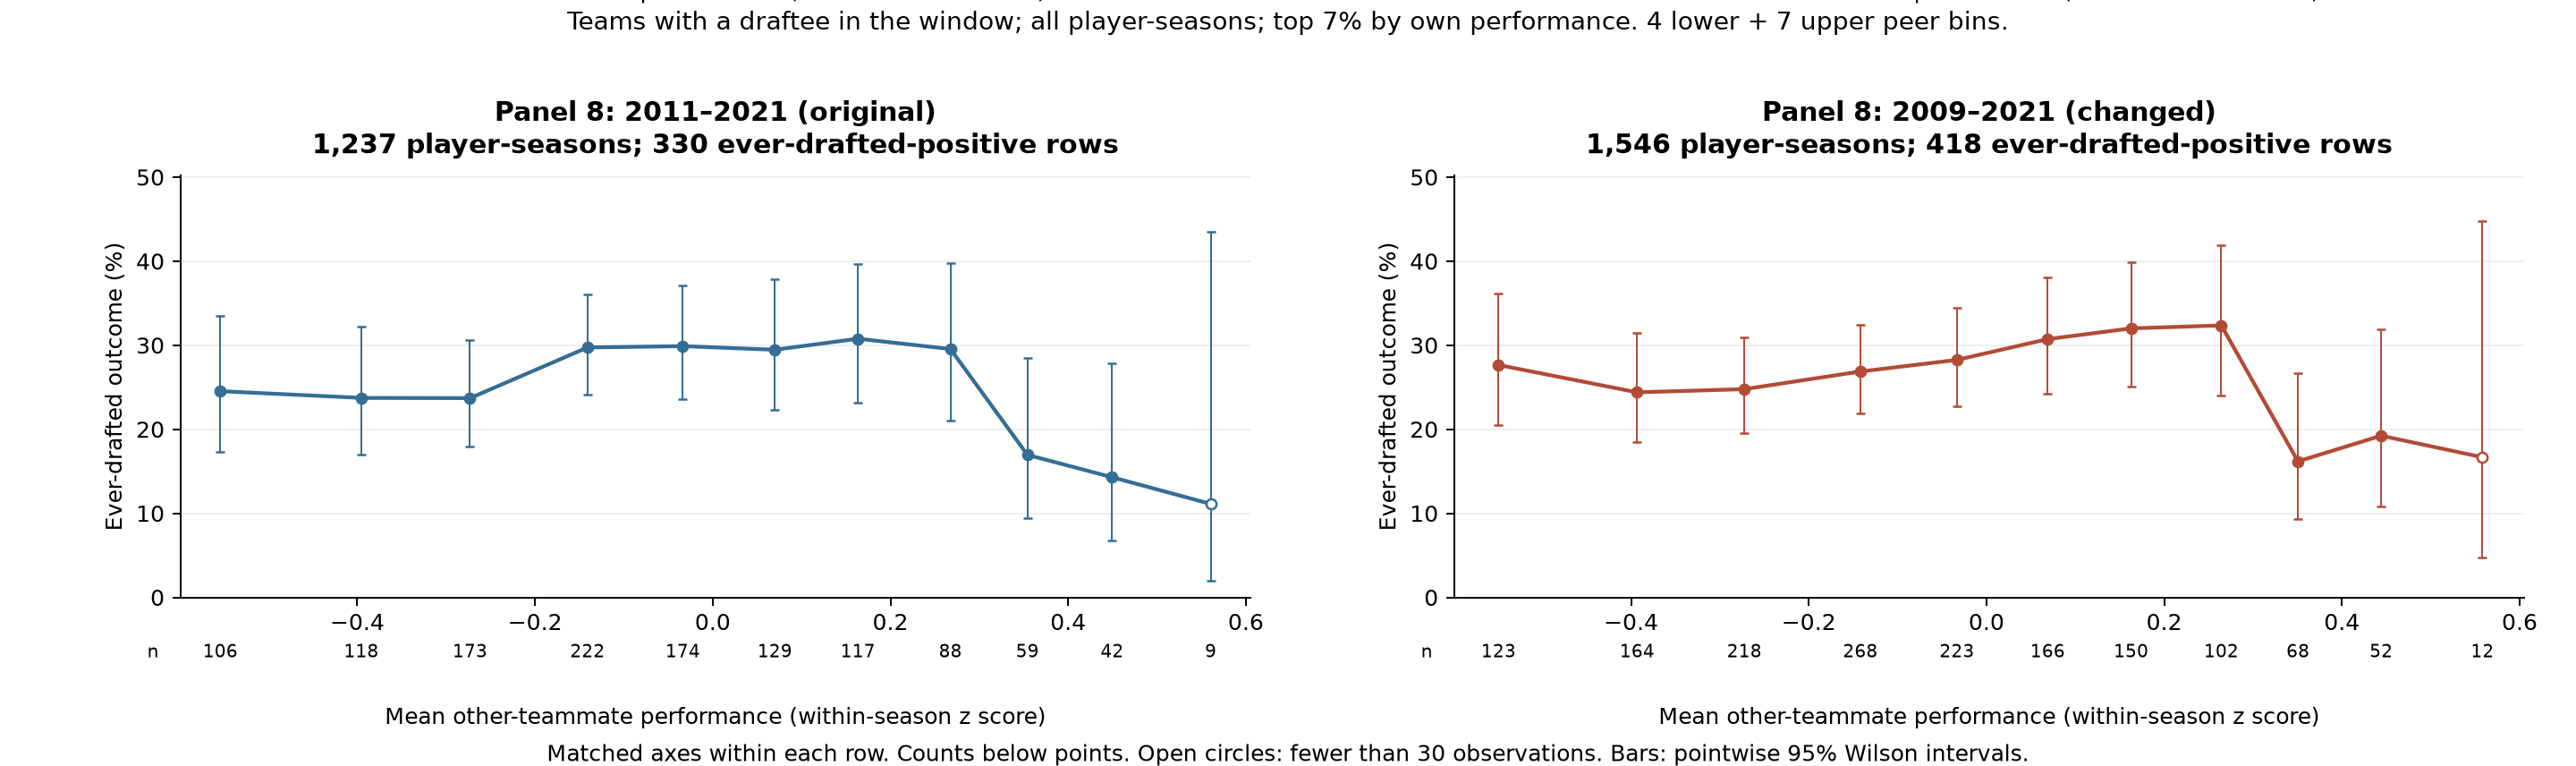

In [11]:
from pathlib import Path
from IPython.display import Image, display
import importlib.util

REBUILD_YEAR_COMPARISON = False

_here = Path.cwd().resolve()
_candidates = [_here, *list(_here.parents)]
_year_script = next((q for parent in _candidates for q in [
    parent / "create_year_window_comparison.py",
    parent / "manuscript_figures/section_4_5/create_year_window_comparison.py",
    parent / "3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/create_year_window_comparison.py",
] if q.exists()), None)
if _year_script is None:
    raise FileNotFoundError("Open this notebook from its project folder so the figure script can be located.")
if REBUILD_YEAR_COMPARISON:
    _spec = importlib.util.spec_from_file_location("year_window_comparison", _year_script)
    _mod = importlib.util.module_from_spec(_spec)
    _spec.loader.exec_module(_mod)
    _figure, _summary = _mod.build()
    import matplotlib.pyplot as plt
    plt.close(_figure)
for _panel_number in (9, 7, 8):
    display(Image(filename=str(_year_script.parent / "year_window_comparison" / f"panel_{_panel_number}_year_comparison.png")))
